# Walkthrough 3: earnings volatility and the IV crush

Before an earnings announcement, options look expensive: their implied volatility is high. The morning after, it collapses, even if the stock barely moves. Option buyers who were right about the direction can still lose money. This notebook explains why, with the model behind the tool's earnings control:

| Where | What |
|---|---|
| `position.py` | `Event`, `base_vol`, `effective_vol`: splitting implied volatility and pricing through the announcement |
| `earnings.py` | `implied_move` (the move the market is pricing) and `event_vols` (the before and after report) |
| `grid.py` | two extra grid dates around the announcement, so the drop shows as a step |

**Running example.** A stock at 166 reports in 5 days. You buy one 30-day straddle (a call and a put, both struck at 165) at 70% implied volatility. Your view of the announcement: a move of about ±8%.

When you finish, do `exercises/earnings.py`; `exercises/test_earnings.py` checks it against the engine.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

import quantcore as qc
from quantcore import black_scholes as bs
from quantcore import scenarios
from quantcore.earnings import event_vols, implied_move
from quantcore.position import base_vol, effective_vol

legs = [qc.Leg("call", 1, strike=165, days=30, vol=0.70), qc.Leg("put", 1, strike=165, days=30, vol=0.70)]
earnings = qc.Event(days=5, move=0.08)
straddle = qc.Position(spot=166.0, rate=0.04, legs=legs, event=earnings)
plain = qc.Position(spot=166.0, rate=0.04, legs=legs)   # the same trade, no announcement

## 1. Variances add

Over the option's life the log price takes many small everyday steps and, on one day, a big jump. If the jump is independent of the everyday moves, their **variances** add (standard deviations do not):

$$\underbrace{\sigma^2 T}_{\text{what the market prices}} \;=\; \underbrace{\sigma_b^2\, T}_{\text{everyday}} \;+\; \underbrace{m^2}_{\text{the jump}}.$$

Here $\sigma$ is the implied volatility you see, $\sigma_b$ the everyday volatility and $m$ the standard deviation of the one-day jump in the log price. Note the units: $\sigma^2 T$ and $m^2$ are both variances of the log price over a stretch of time; $m^2$ is not multiplied by $T$, because the jump happens once whatever the option's life.

Solving for the everyday part:

$$\sigma_b = \sqrt{\frac{\sigma^2 T - m^2}{T}}.$$

In [2]:
T = 30 / 365
by_hand = math.sqrt((0.70**2 * T - 0.08**2) / T)
print(f"by hand: {by_hand:.4f}   engine: {base_vol(legs[0], straddle):.4f}")
print(f"share of the option's variance that is the jump: {0.08**2 / (0.70**2 * T):.1%}")

by hand: 0.6420   engine: 0.6420
share of the option's variance that is the jump: 15.9%


So of the 70% you paid for, only about 64% is everyday volatility. About a sixth of the option's total variance over 30 days comes from one day.

If $\sigma^2 T \le m^2$, the option's volatility is too low to contain the move you typed: no everyday volatility is left. The engine refuses such a position rather than inventing a negative variance:

In [3]:
try:
    qc.Position(spot=166.0, legs=[qc.Leg("call", 1, strike=165, days=10, vol=0.25)], event=earnings)
except ValueError as error:
    print("refused:", error)

refused: leg 1's 25% volatility over 10 days cannot contain a ±8% earnings move.


## 2. Volatility through time

While the announcement is ahead, the jump's variance is still to come, and the option has only $\tau$ years left to spread it over:

$$\sigma_{\text{eff}}(t) = \sqrt{\frac{\sigma_b^2\,\tau + m^2}{\tau}} \quad\text{(before)},\qquad \sigma_{\text{eff}}(t) = \sigma_b \quad\text{(after)}.$$

Two things to notice. At $t = 0$, $\tau = T$ and $\sigma_{\text{eff}} = \sigma$: today's price is exactly the market price you entered. And as the announcement approaches, $\tau$ shrinks while $m^2$ stays, so the implied volatility of a pre-earnings option **rises** day by day, then drops at once. That rising-then-collapsing shape is what traders see on their screens.

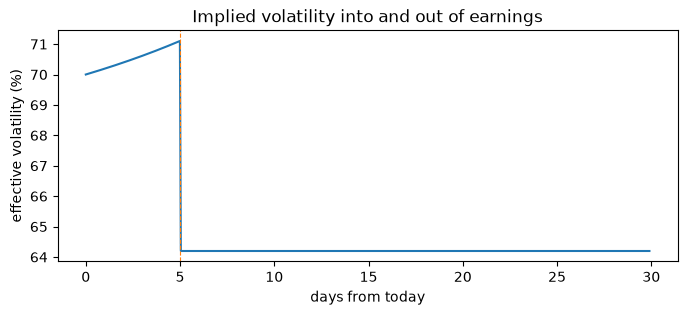

today: 0.7  a moment before: 0.711  after: 0.642


In [4]:
days = np.linspace(0, 29.9, 600)
vols = effective_vol(legs[0], straddle, days)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(days, vols * 100)
ax.axvline(5, color="tab:orange", lw=0.8, ls="--")
ax.set_xlabel("days from today"); ax.set_ylabel("effective volatility (%)"); ax.set_title("Implied volatility into and out of earnings")
plt.show()
print("today:", round(float(effective_vol(legs[0], straddle, 0)), 4),
      " a moment before:", round(float(effective_vol(legs[0], straddle, 5 - 1e-4)), 4),
      " after:", round(float(effective_vol(legs[0], straddle, 5)), 4))

## 3. The crush on a straddle

Price the straddle at the same stock price just before and just after the announcement. The difference is the crush: value lost purely because the uncertainty has been resolved.

In [5]:
S = 166.0
before = float(qc.value(straddle, S, 5 - 1e-4))
after = float(qc.value(straddle, S, 5))
today = float(qc.value(straddle, S, 0))
print(f"today:                    {today:8.2f}")
print(f"a moment before earnings: {before:8.2f}")
print(f"the morning after:        {after:8.2f}")
print(f"the crush:                {before - after:8.2f}")
print(f"5 days of decay with no announcement: {float(qc.value(plain, S, 0) - qc.value(plain, S, 5)):8.2f}")

today:                     2644.10
a moment before earnings:  2453.11
the morning after:         2215.99
the crush:                  237.12
5 days of decay with no announcement:   228.88


Read the numbers together. Without an announcement, five days cost about \$229 of ordinary time decay. With one, the straddle still decays on the way, a little less (about \$191, because the pending jump props it up), and then loses another \$237 overnight: about \$428 in all, nearly twice the ordinary decay, at an unchanged stock price.

**Who wins?** The straddle needs a move big enough to beat the crush. Where are its break-evens the morning after?

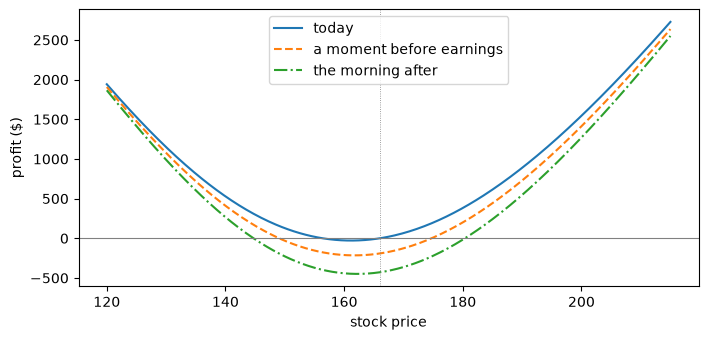

morning-after break-evens near: [144.5 180.2]  i.e. moves of [-13.    8.6] %
the move priced in (one standard deviation): ±8%; average move: ± 6.4 %


In [6]:
prices = np.linspace(120, 215, 381)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(prices, qc.profit(straddle, prices, 0), label="today")
ax.plot(prices, qc.profit(straddle, prices, 5 - 1e-4), "--", label="a moment before earnings")
ax.plot(prices, qc.profit(straddle, prices, 5), "-.", label="the morning after")
ax.axhline(0, color="grey", lw=0.8); ax.axvline(S, color="grey", lw=0.6, ls=":")
ax.set_xlabel("stock price"); ax.set_ylabel("profit ($)"); ax.legend(); plt.show()

curve = np.asarray(qc.profit(straddle, prices, 5))
edges = prices[np.where(np.diff(np.sign(curve)) != 0)[0]]
print("morning-after break-evens near:", np.round(edges, 1), " i.e. moves of", np.round((edges / S - 1) * 100, 1), "%")
print("the move priced in (one standard deviation): ±8%; average move: ±", round(8 * math.sqrt(2 / math.pi), 1), "%")

The morning after, the straddle breaks even only if the stock has fallen about 13% or risen about 9%. The two sides are not mirror images. Measured from the strike, the put side needs about 21 of fall and the call side about 15 of rise. Volatility is a percentage, so an option's remaining time value shrinks as the stock price falls: at lower prices less time value is left, and more intrinsic value is needed to recover the cost. The interest rate tilts it a little further, since it makes calls slightly dearer and puts slightly cheaper. The market prices an average move of about ±6.4% (one standard deviation is ±8%, and the average of a normal jump's size is $m\sqrt{2/\pi}$). Buying the straddle is a bet that the real move beats what is priced in, not just that the stock moves.

## 4. A calendar spread across earnings

Now two expiries, both after the announcement: sell a 7-day call and buy a 35-day call, both struck at 165. The jump is the same size for both, but the near option has much less time to spread it over, so its implied volatility carries far more of it. To be consistent, both legs share one everyday volatility, here the 64.2% from above, and each leg's implied volatility is built from it.

In [7]:
b, m = base_vol(legs[0], straddle), 0.08
implied = lambda d: math.sqrt(b * b + m * m / (d / 365))
near_vol, far_vol = implied(7), implied(35)
print(f"implied vols: 7-day {near_vol:.1%}, 35-day {far_vol:.1%}")
calendar = qc.Position(spot=166.0, rate=0.04, event=earnings, legs=[
    qc.Leg("call", -1, strike=165, days=7, vol=near_vol),
    qc.Leg("call", 1, strike=165, days=35, vol=far_vol),
])
for leg_index, base, vol_before, vol_after, weight in event_vols(calendar):
    print(f"leg {leg_index + 1}: {vol_before:.1%} -> {vol_after:.1%}")
cb, ca = float(qc.value(calendar, S, 5 - 1e-4)), float(qc.value(calendar, S, 5))
print(f"calendar value a moment before: {cb:.2f}   the morning after: {ca:.2f}   change: {ca - cb:+.2f}")

implied vols: 7-day 86.4%, 35-day 69.2%
leg 1: 86.4% -> 64.2%
leg 2: 69.2% -> 64.2%
calendar value a moment before: 731.86   the morning after: 921.89   change: +190.03


Both legs crush to the same everyday volatility, but the short near leg falls much further, so the calendar **gains** from the announcement at an unchanged price. This is why desks sell front-month volatility into earnings and own the back month. The trade still loses if the stock moves a lot, because a calendar is short gamma near the strike.

## 5. What move is the market pricing?

Section 4 built two implied volatilities from an everyday volatility and a jump. A trader faces the opposite problem: two prices on the screen, and the question "what move is priced in?". Two equations, two unknowns:

$$\sigma_1^2 T_1 = \sigma_b^2 T_1 + m^2,\qquad \sigma_2^2 T_2 = \sigma_b^2 T_2 + m^2.$$

Subtract to remove $m^2$:

$$\sigma_b^2 = \frac{\sigma_2^2 T_2 - \sigma_1^2 T_1}{T_2 - T_1},\qquad m^2 = \sigma_1^2 T_1 - \sigma_b^2 T_1.$$

In [8]:
result = implied_move(7, near_vol, 35, far_vol)
print(f"recovered move {result.move:.4f} (true 0.08)   everyday vol {result.base_vol:.4f} (true {b:.4f})")
print(f"average move, up or down: ±{result.expected_abs_move:.2%}")
print(f"share of the 7-day option's variance that is the jump: {result.event_variance_share:.0%}")
try:
    implied_move(7, 0.40, 35, 0.55)
except ValueError as error:
    print("with the later expiry dearer:", error)

recovered move 0.0800 (true 0.08)   everyday vol 0.6420 (true 0.6420)
average move, up or down: ±6.38%
share of the 7-day option's variance that is the jump: 45%
with the later expiry dearer: the later expiry is the more expensive one, so these prices imply no earnings premium


The refusal matters: if the later expiry has the higher volatility, these two prices imply no earnings premium at all (or a term structure the one-base-volatility assumption cannot explain). The tool says so rather than printing a negative variance's square root.

## 6. Check it by simulation

The model says: an everyday diffusion at $\sigma_b$ plus one normal jump in the log price, sized $m$, prices exactly like Black-Scholes at $\sigma_{\text{eff}}$. Simulate both pieces and price the call by averaging its discounted payoff. The jump's mean is $-\tfrac12 m^2$, the same convexity correction as in Walkthrough 2, so the expected price is unchanged by the jump.

In [9]:
rng = np.random.default_rng(3)
n, r = 2_000_000, 0.04
log_s = (math.log(S) + (r - 0.5 * b * b) * T + b * math.sqrt(T) * rng.standard_normal(n)
         - 0.5 * m * m + m * rng.standard_normal(n))
payoff = math.exp(-r * T) * np.maximum(np.exp(log_s) - 165, 0)
est, se = payoff.mean(), payoff.std() / math.sqrt(n)
model = float(bs.price(S, 165, T, float(effective_vol(legs[0], straddle, 0)), r, 0, "call"))
print(f"simulated {est:.4f} +/- {1.96 * se:.4f}   Black-Scholes at sigma_eff {model:.4f}")

simulated 13.9632 +/- 0.0310   Black-Scholes at sigma_eff 13.9913


Agreement within the simulation's error. One subtlety for interviews: this is exact here only because the jump is **normal in the log price**. Sum two independent normals and you get a normal, so the whole log-price distribution is still Gaussian, just wider. With a lumpier jump (say, either +10% or −10%), Black-Scholes at one effective volatility would misprice options away from the money.

## 7. The P/L explain across the announcement

Walkthrough 2's P/L explain uses the Greeks measured today. Run it across the announcement:

In [10]:
for name, pos in (("no announcement", plain), ("through earnings", straddle)):
    e = scenarios.explain(pos, price_move=0.0, days_passed=5)
    print(f"{name:>17}: theta predicts {e.theta:+8.2f}   actual {e.actual:+8.2f}   unexplained {e.unexplained:+8.2f}")

  no announcement: theta predicts  -218.74   actual  -228.88   unexplained   -10.14
 through earnings: theta predicts  -183.92   actual  -428.11   unexplained  -244.19


Today's theta knows nothing about the jump that is about to vanish, so more than half of the loss shows up as **unexplained**. A risk report that only multiplies Greeks by moves would miss an earnings crush entirely. Desks handle this by tracking event volatility separately from everyday volatility, which is exactly the split this model makes.

## 8. Where this is wrong

1. **The jump size is known.** Here $m$ is an input. In reality nobody knows how big the reaction will be, and that uncertainty is priced too.
2. **Normal in the log price.** Real reactions are lumpier and often skewed, which section 6 showed is the case where one effective volatility stops being exact.
3. **One announcement**, on a known day, before the open.
4. **Shocks move only the everyday volatility.** The tool's volatility slider and scenario grid never change $m$.
5. **One shared everyday volatility** across expiries in the implied-move calculation. Real term structures rarely oblige exactly.
6. **American options** in the tool use the binomial tree at $\sigma_{\text{eff}}$, not a tree with a jump in it, which slightly misstates early exercise around the announcement.

## 9. Check yourself

Answer out loud, without code:

1. Why do variances add, but not volatilities? What assumption does that need?
2. Why does a pre-earnings option's implied volatility *rise* as the announcement approaches, if nothing else changes?
3. A straddle into earnings loses money even though the stock moved 5%. How can that be, and what move did it need?
4. Why does a short-front, long-back calendar spread gain from the crush at an unchanged price?
5. Your two expiries give $\sigma_b^2 < 0$ in the implied-move formula. What does that tell you about the prices?

Then open `exercises/earnings.py`.